In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [3]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_128_train/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(128,128),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_128_test/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(128,128),
    seed=42,
    shuffle=False,
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 13068 files belonging to 2 classes.
Using 10455 files for training.
Using 2613 files for validation.
Found 3268 files belonging to 2 classes.


In [4]:
# #Correct model
model = keras.models.Sequential()
model.add(keras.Input(shape=(128,128,3)))

model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=64, kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=128, kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.BatchNormalization())

model.add(layers.Flatten())

model.add(layers.Dense(units=128, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=2, activation='softmax'))

# model = keras.models.Sequential()
# model.add(keras.Input(shape=(128,128,3)))
# model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))

# model.add(layers.Flatten())

# model.add(layers.Dense(units=64, activation='relu'))
# model.add(layers.Dense(units=1, activation='sigmoid'))

model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=5)

In [5]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    class_weight={0: 0.65, 1: 1}
    )

Epoch 1/50
654/654 [==============================] - 21s 25ms/step - loss: 0.5301 - categorical_accuracy: 0.6766 - val_loss: 0.6092 - val_categorical_accuracy: 0.7225
Epoch 2/50
654/654 [==============================] - 11s 17ms/step - loss: 0.4814 - categorical_accuracy: 0.7180 - val_loss: 0.5837 - val_categorical_accuracy: 0.7107
Epoch 3/50
654/654 [==============================] - 11s 17ms/step - loss: 0.4701 - categorical_accuracy: 0.7216 - val_loss: 0.6068 - val_categorical_accuracy: 0.7229
Epoch 4/50
654/654 [==============================] - 12s 19ms/step - loss: 0.3581 - categorical_accuracy: 0.8242 - val_loss: 0.4646 - val_categorical_accuracy: 0.8305
Epoch 5/50
654/654 [==============================] - 12s 19ms/step - loss: 0.2626 - categorical_accuracy: 0.8842 - val_loss: 0.3675 - val_categorical_accuracy: 0.8722
Epoch 6/50
654/654 [==============================] - 12s 18ms/step - loss: 0.2111 - categorical_accuracy: 0.9119 - val_loss: 0.2830 - val_categorical_accuracy:

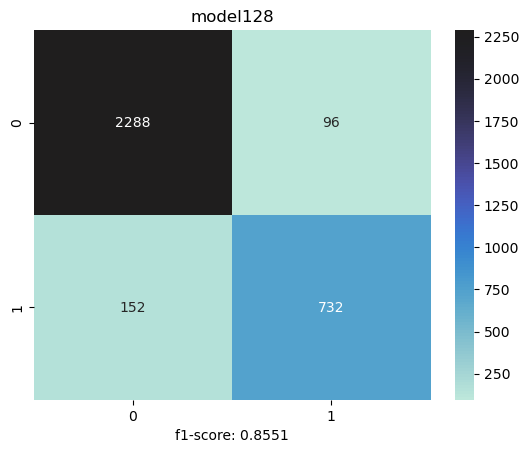

In [6]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model128')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model128.png')
plt.show()

In [7]:
model.save('./trained_models/model128')

INFO:tensorflow:Assets written to: ./trained_models/model128\assets


INFO:tensorflow:Assets written to: ./trained_models/model128\assets


In [4]:
model128 = keras.models.load_model('./trained_models/model128_test')
model128.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 32)        4736      
                                                                 
 batch_normalization (BatchN  (None, 64, 64, 32)       128       
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 batch_normalization_1 (Batc  (None, 32, 32, 64)       256       
 hNormalization)                                                 
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 64)        36928     
                                                                 
 batch_normalization_2 (Batc  (None, 32, 32, 64)       2

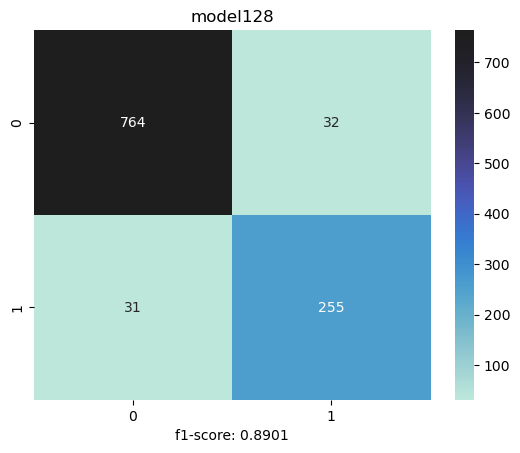

In [7]:
array = test_model(model128, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model128')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model128.png')
plt.show()